# Target and Past Volatility Features

It builds the panel: one row per report, with the volatility of the following 21 sessions (target variable) and the volatility of the previous sessions (last day, week and month).

`t0` is the first tradable session of a report.

### Setup

In [141]:
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [142]:
ROOT = Path.cwd().parent          # One step back
BRONZE = ROOT / "data" / "bronze"
SILVER = ROOT / "data" / "silver"
GOLD = ROOT / "data" / "gold"

PRICES = BRONZE / "prices"        # One parquet per ticker

GOLD.mkdir(parents=True, exist_ok=True)

HORIZON = 21    # Sessions of the target window (about one trading month), as in configs/pilot.yaml
MONTH = 22      # Sessions of the monthly feature: Corsi uses 22 instead of 21
WEEK = 5        # Sessions of the weekly feature

TARGET = f"target_{HORIZON}d"
HAR_COLS = ["vol_last_day", "vol_last_week", "vol_last_month"]

## EDA

In [143]:
universe = pd.read_parquet(SILVER / "universe.parquet")
filings = pd.read_parquet(SILVER / "filings.parquet")

universe.head()

,cik,ticker,company,sector,sic,sic_description,fiscal_year_end
0,789019,MSFT,MICROSOFT CORP,Technology,7372,Services-Prepackaged Software,0630
1,50863,INTC,INTEL CORP,Technology,3674,Semiconductors & Related Devices,1226
2,1341439,ORCL,ORACLE CORP,Technology,7372,Services-Prepackaged Software,0531
3,51143,IBM,INTERNATIONAL BUSINESS MACHINES CORP,Technology,3570,Computer & office Equipment,1231
4,804328,QCOM,QUALCOMM INC/DE,Technology,3663,Radio & Tv Broadcasting & Communications Equip...,0927


In [144]:
filings.head()

,cik,accession_number,form,filing_date,report_date,accepted_at_utc,first_tradable_date
0,789019,0001564590-19-027952,10-K,2019-08-01,2019-06-30,2019-08-01 20:09:55+00:00,2019-08-02
1,789019,0001564590-18-019062,10-K,2018-08-03,2018-06-30,2018-08-03 15:03:33+00:00,2018-08-06
2,789019,0001564590-17-014900,10-K,2017-08-02,2017-06-30,2017-08-02 20:15:01+00:00,2017-08-03
3,789019,0001193125-16-662209,10-K,2016-07-28,2016-06-30,2016-07-28 20:12:18+00:00,2016-07-29
4,789019,0001193125-15-272806,10-K,2015-07-31,2015-06-30,2015-07-31 19:07:52+00:00,2015-08-03


In [145]:
# The ticker is needed to find the price file of each report
filings = filings.merge(universe[["cik", "ticker"]], on="cik", how="left")
filings.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype              
---  ------               --------------  -----              
 0   cik                  300 non-null    int64              
 1   accession_number     300 non-null    str                
 2   form                 300 non-null    str                
 3   filing_date          300 non-null    datetime64[us]     
 4   report_date          300 non-null    datetime64[us]     
 5   accepted_at_utc      300 non-null    datetime64[us, UTC]
 6   first_tradable_date  300 non-null    datetime64[ms]     
 7   ticker               300 non-null    str                
dtypes: datetime64[ms](1), datetime64[us, UTC](1), datetime64[us](2), int64(1), str(3)
memory usage: 26.8 KB


## Daily Variance

The daily variance is estimated with **Garman-Klass plus the overnight jump**:

- Garman-Klass uses the high, low, open and close of the session, so it captures the movement *during* the session.
- The overnight jump captures the movement between sessions, which is where the reaction to a report published after the close appears.

Everything is in **percentage**: the variance is multiplied by 10,000 ($\%^2$).

In [146]:
def garman_klass_with_overnight_jump(prices: pd.DataFrame) -> pd.Series:
    """
    Return the daily variance (Garman-Klass + overnight jump) in % squared.

    Parameters
    ----------
    prices : pandas.DataFrame
        Adjusted daily OHLC prices indexed by date (columns Open, High, Low, Close).

    Returns
    -------
    pandas.Series
        Daily variance in % squared. The first day is NaN: it has no previous close.
    """
    log_hl = np.log(prices["High"] / prices["Low"])
    log_co = np.log(prices["Close"] / prices["Open"])

    gk = 0.5 * log_hl**2 - (2 * np.log(2) - 1) * log_co**2          # Garman-Klass (open to close)
    jump = np.log(prices["Open"] / prices["Close"].shift(1)) ** 2   # close(t-1) to open(t), NaN on the first day

    return 10_000 * (gk + jump)                                     # variance in % squared

In [147]:
# Microsoft will be used as the guinea pig
msft = pd.read_parquet(PRICES / "MSFT.parquet")
msft_var = garman_klass_with_overnight_jump(msft)

msft_var.head()

Date
2009-01-02          NaN
2009-01-05     3.943926
2009-01-06     2.998645
2009-01-07    11.515876
2009-01-08     3.215855
dtype: float64

In [148]:
# Only the first day should be missing. It is kept as NaN, not as zero
msft_var.isna().sum()

np.int64(1)

In [149]:
# Days with zero or negative variance, across every ticker of the universe
non_positive = []
for ticker in universe["ticker"]:
    prices = pd.read_parquet(PRICES / f"{ticker}.parquet")
    var = garman_klass_with_overnight_jump(prices)

    non_positive_var_positions = (var <= 0)

    non_positive_var    = var[non_positive_var_positions]
    non_positive_prices = prices[non_positive_var_positions]

    non_positive.append(non_positive_prices.assign(ticker=ticker, var=non_positive_var))

pd.concat(non_positive)

Price,Close,High,Low,Open,Volume,ticker,var
Date,,,,,,,
2015-01-02,2.67,2.67,2.67,2.67,0,AMD,0.0


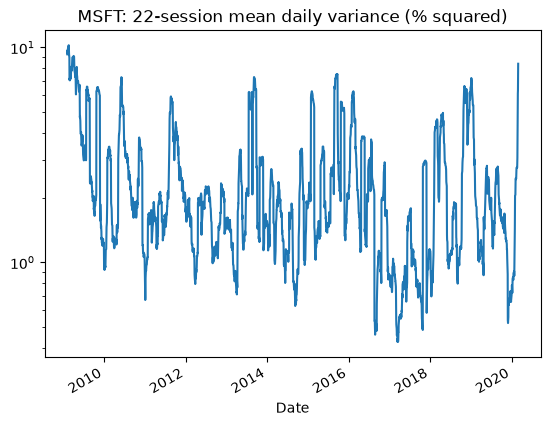

In [150]:
# Mean variance of the last 22 sessions, log scale (the variance spans more than one order of magnitude)
msft_var.rolling(MONTH).mean().plot(logy=True, title="MSFT: 22-session mean daily variance (% squared)");

**Findings**
 - Only the first day is NaN, as expected.
 - There is one day with zero variance in the whole universe: AMD on 2015-01-02. Open, high, low and close are all 2.67 and the volume is 0, so it is a day without trading data in yfinance, not a real day without movement. It is kept: the features and the target use the mean of several days, which stays positive, and it is not the last day (`t0 − 1`) of any AMD report, so no log of zero appears in the panel.
 - 2009: the highest level (about 10 $\%^2$), the tail end of the financial crisis, falling over the course of the year.
 - Mid-2010 and August 2011: the two flare-ups of the European debt crisis.
 - August 2015 and early 2016: the China devaluation and the oil sell-off.
 - 2017: the calmest period of the series, with a variance of 0.4 to 0.5 $\%^2$, about twenty times lower than in 2009.
 - 2018: volatility returns, in February and at the end of the year.
 - February 2020: the start of COVID, at the end of the series.

## One Report by Hand

Before writing any general function, the target and the three features are computed for a single report. The windows are sliced **by position** (`iloc`), not by date, so weekends and holidays do not matter.

The first and last date of each window are printed to check them against a calendar. It is the most important check of the notebook.

In [151]:
# First MSFT report of the sample
report = filings[filings["ticker"] == "MSFT"].sort_values("first_tradable_date").iloc[0]
t0 = report["first_tradable_date"]

i = msft_var.index.get_loc(t0)   # position of t0 in the series
t0

Timestamp('2010-08-02 00:00:00')

In [152]:
windows = {
    "target": msft_var.iloc[i : i + HORIZON],
    "last day": msft_var.iloc[i - 1 : i],
    "last week": msft_var.iloc[i - WEEK : i],
    "last month": msft_var.iloc[i - MONTH : i],
}

rows = []
for name, w in windows.items():
    rows.append({
        "window": name,
        "first": w.index[0].date(),
        "last": w.index[-1].date(),
        "sessions": len(w),
        "log_mean_var": np.log(w.mean()),   # log of the mean, not mean of the logs
    })

summary = pd.DataFrame(rows).set_index("window")

summary

,first,last,sessions,log_mean_var
window,,,,
target,2010-08-02,2010-08-30,21,0.702264
last day,2010-07-30,2010-07-30,1,1.092409
last week,2010-07-26,2010-07-30,5,0.764217
last month,2010-06-30,2010-07-30,22,1.067925


**Findings**
 - `t0` is Monday 2010-08-02, so the last day of the features is Friday 2010-07-30: weekends are skipped.
 - The monthly window starts on 2010-06-30 and has 22 sessions: July 5th (Independence Day holiday) is skipped.
 - The target starts at `t0` and ends on 2010-08-30, 21 sessions later.
 - The four windows are the expected ones, and the features end the session before the target starts.

*Note: the overnight jump of `t0` uses the close of `t0 − 1`. This is not a leak: a report accepted at 17:00 of `t0 − 1` is released after that close, so the jump of `t0` is exactly the reaction to the report, and it belongs to the target.*

## Target and Feature Functions

In [153]:
def forward_log_variance(var: pd.Series, t0: pd.Timestamp, horizon: int = HORIZON) -> float:
    """
    Return the log of the mean daily variance over the `horizon` sessions starting at `t0` (included).

    Parameters
    ----------
    var : pandas.Series
        Daily variance (% squared) indexed by session date.
    t0 : pandas.Timestamp
        First tradable session of the report.
    horizon : int
        Number of sessions of the window.

    Returns
    -------
    float
        Log mean variance, or NaN if `t0` is not a session or the window is incomplete.
    """
    if t0 not in var.index:
        return np.nan

    i = var.index.get_loc(t0)
    window = var.iloc[i : i + horizon]   # t0 included

    if len(window) < horizon or window.isna().any():
        return np.nan                    # never computed with fewer days than due

    return np.log(window.mean())

In [154]:
def past_volatility_features(var: pd.Series, t0: pd.Timestamp) -> tuple[float, float, float]:
    """
    Return the HAR features of a report, using only the sessions up to `t0 - 1`.

    Parameters
    ----------
    var : pandas.Series
        Daily variance (% squared) indexed by session date.
    t0 : pandas.Timestamp
        First tradable session of the report.

    Returns
    -------
    tuple[float, float, float]
        Log variance of the last day, log mean variance of the last week (5 sessions)
        and of the last month (22 sessions). NaN if `t0` is not a session or there
        are not enough past sessions.
    """
    nan = (np.nan, np.nan, np.nan)

    if t0 not in var.index:
        return nan

    i = var.index.get_loc(t0)

    if i < MONTH:
        return nan                                 # not enough past sessions

    last_month = var.iloc[i - MONTH : i]           # ends at t0 - 1, t0 excluded
    if last_month.isna().any():
        return nan

    vol_last_day = np.log(var.iloc[i - 1])
    vol_last_week = np.log(var.iloc[i - WEEK : i].mean())
    vol_last_month = np.log(last_month.mean())

    return vol_last_day, vol_last_week, vol_last_month

In [155]:
# The functions must give the same values as the computation by hand
assert forward_log_variance(msft_var, t0) == np.log(windows["target"].mean())
assert past_volatility_features(msft_var, t0) == (
    np.log(windows["last day"].iloc[0]),
    np.log(windows["last week"].mean()),
    np.log(windows["last month"].mean()),
)

### Test

The table below describes the edge cases. Returning NaN is reasonable; returning a number computed with fewer days than due is not.

| Case | `t0` | Expected |
| --- | --- | --- |
| `t0` is not a session | a Saturday | NaN (target and features) |
| Fewer than 22 sessions before `t0` | 10th session of the prices | NaN (features) |
| Fewer than 21 sessions after `t0` | 10th last session of the prices | NaN (target) |

In [156]:
saturday = pd.Timestamp("2015-08-01")
early = msft_var.index[10]
late = msft_var.index[-10]

assert np.isnan(forward_log_variance(msft_var, saturday))
assert np.isnan(past_volatility_features(msft_var, saturday)).all()
assert np.isnan(past_volatility_features(msft_var, early)).all()
assert np.isnan(forward_log_variance(msft_var, late))

### Leakage Tests

1. **Change the future.** Multiply by 100 the variance of every day from `t0` onwards. The three features **must not change**.
2. **Change the past.** Multiply by 100 the variance of every day before `t0`. The target **must not change**.

If either fails, a day is leaking into the wrong window.

In [157]:
future_changed = msft_var.copy()
future_changed.iloc[i:] *= 100      # t0 and after

past_changed = msft_var.copy()
past_changed.iloc[:i] *= 100        # sessions before t0, t0 excluded

assert past_volatility_features(future_changed, t0) == past_volatility_features(msft_var, t0)
assert forward_log_variance(past_changed, t0) == forward_log_variance(msft_var, t0)

**Findings**
 - The functions match the computation by hand, return NaN in the three edge cases and pass both leakage tests.

## Panel of Reports

The daily variance of each company is computed **only once**, and then the target and the features of each of its reports.

In [158]:
rows = []

for ticker, group in filings.groupby("ticker"):
    var = garman_klass_with_overnight_jump(pd.read_parquet(PRICES / f"{ticker}.parquet"))  # once per ticker

    for f in group.itertuples(index=False):
        vol_d, vol_w, vol_m = past_volatility_features(var=var, t0=f.first_tradable_date)
        rows.append({
            "cik": f.cik,
            "accession_number": f.accession_number,
            "first_tradable_date": f.first_tradable_date,
            TARGET: forward_log_variance(var=var, t0=f.first_tradable_date, horizon=HORIZON),
            "vol_last_day": vol_d,
            "vol_last_week": vol_w,
            "vol_last_month": vol_m,
        })

panel = pd.DataFrame(rows)
panel.head()

,cik,accession_number,first_tradable_date,target_21d,vol_last_day,vol_last_week,vol_last_month
0,6281,0000006281-19-000144,2019-11-27,0.432181,3.345028,2.059601,1.271179
1,6281,0000006281-18-000126,2018-11-27,1.689609,1.621941,1.886458,1.612093
2,6281,0000006281-17-000144,2017-11-24,0.427737,1.191778,1.210928,0.640200
3,6281,0000006281-16-000097,2016-11-22,1.240827,-0.295648,0.183708,0.859414
4,6281,0000006281-15-000044,2015-11-24,1.577325,1.620208,0.780988,1.113555


### Feature Exploration & Validation

In [159]:
panel.shape

(300, 7)

In [160]:
panel.isna().sum()

cik                    0
accession_number       0
first_tradable_date    0
target_21d             0
vol_last_day           0
vol_last_week          0
vol_last_month         0
dtype: int64

**Findings**
 - 300 rows, one per report, and no NaN: every report has at least 22 sessions before `t0` (prices start in January 2009, reports in 2010) and 21 after it (prices end in February 2020).

In [161]:
# All columns are logs of variances in % squared, so the means should be on the same scale
panel[[TARGET] + HAR_COLS].describe()

,target_21d,vol_last_day,vol_last_week,vol_last_month
count,300.000000,300.000000,300.000000,300.000000
mean,0.530297,0.377767,0.523634,0.748782
std,0.721203,0.971413,0.795685,0.780248
min,-1.011378,-1.687257,-0.941094,-0.791888
25%,-0.010008,-0.324430,-0.092459,0.245853
50%,0.535029,0.301153,0.479180,0.696011
75%,0.941302,1.066753,0.987905,1.238846
max,2.755094,3.485150,2.888421,3.268821


In [162]:
# Correlation of the target with each feature
panel[[TARGET] + HAR_COLS].corr()[TARGET]

target_21d        1.000000
vol_last_day      0.486071
vol_last_week     0.583749
vol_last_month    0.736509
Name: target_21d, dtype: float64

**Findings**
 - The four means are on the same scale (0.38 to 0.75), as all of them are logs of variances in $\%^2$.
 - The last day has the largest standard deviation (0.97): a single day is the noisiest measure.
 - The monthly feature has the highest correlation with the target (0.74), followed by the weekly (0.58) and the daily (0.49).

## HAR Check

`target_21d ~ vol_last_day + vol_last_week + vol_last_month`, estimated by OLS with every report.

This is a qualitative check:

- The three coefficients, **positive**.
- Their sum, **lower than 1**.
- A reasonable $R^2$ (past volatility explains a good part of future volatility).

Corsi's values are not expected: here the target is 21 days ahead, the data is daily and 30 companies are mixed.

In [163]:
har = sm.OLS(panel[TARGET], sm.add_constant(panel[HAR_COLS]), missing="drop").fit()

print(har.summary())

                            OLS Regression Results                            
Dep. Variable:             target_21d   R-squared:                       0.549
Model:                            OLS   Adj. R-squared:                  0.544
Method:                 Least Squares   F-statistic:                     119.9
Date:                Sat, 28 Nov 2026   Prob (F-statistic):           7.78e-51
Time:                        12:52:36   Log-Likelihood:                -207.83
No. Observations:                 300   AIC:                             423.7
Df Residuals:                     296   BIC:                             438.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.0316      0.039      0.

In [164]:
coefs = har.params[HAR_COLS]

print(f"All coefficients positive: {(coefs > 0).all()}")
print(f"Sum of coefficients: {coefs.sum():.3f}")
print(f"R-squared: {har.rsquared:.3f}")
print(f"Reports lost for lack of data: {len(panel) - int(har.nobs)}")

All coefficients positive: True
Sum of coefficients: 0.703
R-squared: 0.549
Reports lost for lack of data: 0


**Findings**
 - The three coefficients are positive and their sum is 0.703, lower than 1: the validation criterion is met.
 - $R^2$ = 0.549: past volatility explains more than half of the variance of the target.
 - No report is lost for lack of data.
 - Only the monthly feature is significant (0.62, p < 0.001); the daily (p = 0.11) and the weekly (p = 0.83) are not. The three features are highly correlated, and with a 21-day target the monthly one absorbs most of the information.

## Save Data

In [165]:
# 1 row per report: the target and the past volatility features
PANEL_COLS = ["cik", "accession_number", "first_tradable_date", TARGET] + HAR_COLS

panel = panel[PANEL_COLS]
panel.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   cik                  300 non-null    int64         
 1   accession_number     300 non-null    str           
 2   first_tradable_date  300 non-null    datetime64[ms]
 3   target_21d           300 non-null    float64       
 4   vol_last_day         300 non-null    float64       
 5   vol_last_week        300 non-null    float64       
 6   vol_last_month       300 non-null    float64       
dtypes: datetime64[ms](1), float64(4), int64(1), str(1)
memory usage: 22.4 KB


In [166]:
panel.to_parquet(GOLD / "panel.parquet")